# ASL Citizen SLR — Green Computing, Model 5/5: TinyMSLR-Style Hybrid (CNN + Transformer)

**Course:** CSE 407 — Green Computing
**Paper:** *Quantifying the Carbon Cost of Accuracy: An Energy-Aware Comparison of CNN and Transformer Architectures for Word-Level Sign Language Recognition*
**This notebook is 5 of 5 — the last one** in the model family requested by faculty feedback on the proposal.

**Source:** Lamaakal, I. et al., *"An explainable hybrid CNN–transformer model for sign language recognition on edge devices using adaptive fusion and knowledge distillation"*, Scientific Reports 16, 7143 (2026), https://www.nature.com/articles/s41598-026-38478-8 — the paper faculty linked in the feedback, proposing **TinyMSLR**.

## Changelog / where this fits — read this one before running

### What TinyMSLR actually is, per the paper
TinyMSLR is a **hybrid CNN–Transformer** model with three distinctive pieces, all implemented
here:
1. **Dual encoder branches:** a ConvNeXt-Tiny CNN branch (local/spatial cues) and a Swin
   Transformer branch (global/contextual cues), each producing a 768-dim clip-level descriptor.
2. **A GRU inserted into the CNN branch's residual path** (paper Eqs. 8-11) to give the CNN
   stream explicit short-range temporal continuity, since plain frame-wise convolutions alone
   can fragment motion across frames.
3. **An adaptive fusion gate** (Eqs. 13-15): the two branches' features are concatenated, passed
   through a small MLP, and turned into per-sample softmax weights that decide how much to trust
   each branch for that particular clip — plus **auxiliary classification heads** on each branch
   (Eq. 12) for deep supervision during training.

All three are implemented faithfully in Section 5 below (`ConvNeXtTinyGRUStream`,
`SwinTinyStream`, `TinyMSLRHybridModel`), with the paper's own equation numbers cited inline in
the code comments so you can check the mapping directly.

### Important reproducibility caveat — read before citing this notebook's parameter count
The paper states its final distilled student has **~2.7M parameters and 7.2MB** on disk, while
in the same section describing the student's *own* architecture, it names the branches as
"a ConvNeXt-Tiny encoder... with a Swin Transformer encoder." Standard ConvNeXt-Tiny is ~28M
parameters and standard Swin-Tiny is ~28M parameters on their own — together far more than 2.7M,
even before the fusion/classifier layers. The paper does not publish the exact reduced channel
widths or layer counts for whatever compressed "ConvNeXt-Tiny-like" and "Swin-Tiny-like" modules
actually produced the 2.7M-parameter figure; only the (much larger) **teacher** networks are
named as standard-scale (ConvNeXt-Base, Swin-B). **This notebook cannot reproduce the paper's
stated 2.7M-parameter footprint**, because the exact compressed-backbone configuration needed to
do so isn't published.

Rather than guess at an arbitrary channel-width reduction and present a made-up number as "the"
TinyMSLR parameter count, this notebook implements the architecture's **design** faithfully at
**standard ConvNeXt-Tiny + Swin-Tiny scale** — the actual named backbones — and reports the real
resulting parameter count and energy/carbon figures for *that*. Flag this explicitly in the
paper: `model_card["param_count_matches_paper_2_7m_claim"] = False`. This is itself a legitimate,
citable finding for a green-computing paper — a published "TinyML" model's efficiency claims can
depend on an unpublished compression recipe, which matters for anyone trying to reproduce or
build on it.

### Second scope cut: no knowledge distillation
The paper's headline compactness result relies on **dual-teacher KD** (Eqs. 17-19): two
high-capacity teachers (ConvNeXt-Base, Swin-B) are pretrained to convergence first, then frozen,
and the student is trained against a temperature-softened blend of their outputs. Reproducing
that faithfully means training two additional large models to convergence — each with its own
full training energy/carbon cost — before this student's own training could even start. That's
a substantially larger undertaking than any other single notebook in this family, and KD mainly
shapes *training* dynamics and final accuracy rather than the *deployed* model's inference-time
compute, which is this green-computing comparison's actual focus (RQ1-RQ3 are about the deployed
model's cost, not how it got trained).

**This notebook trains the student with ground-truth CE + auxiliary-head supervision only**
(paper Eq. 20-21, `L = CE(y_hat, y) + lambda_1 * L_aux`, with the published `lambda_1 = 0.4`) and
**omits the `lambda_2 * L_distill` term entirely** (`model_card["kd_implemented"] = False`).
Expect this notebook's accuracy to plausibly trail a true dual-teacher-distilled TinyMSLR as a
result — that's a documented, known gap, not a bug, and worth stating as such in the paper rather
than presenting this notebook's numbers as "TinyMSLR" without qualification.

### What carries over unchanged from notebooks 1-4
- Same cache, same manifest/top-K logic, same `TOP_K_CLASSES=100`.
- Same green-computing constants: `GRID_CARBON_INTENSITY_KG_PER_KWH=0.475`,
  `EXPECTED_INFERENCE_VOLUME=100_000`, `INFERENCE_PROFILING_PASSES=3`.
- Same training hyperparameters (`BATCH_SIZE=8`, `LR=1e-4`, epoch budget) for the controlled
  comparison — and the same standing note: two full-scale ImageNet backbones running in parallel
  makes this the heaviest model to actually train/run in the family, so if it OOMs, record that
  as a result rather than silently shrinking the batch size.
- Same 16-frame appearance-stream input as notebooks 1-3 (unlike notebook 4 — neither ConvNeXt
  nor Swin has a frame-count-locked pretrained temporal component to preserve).
- Not resumable across sessions, for the same energy-accounting reason as every other notebook.
- Produces `green_metrics_tinymslr_hybrid_no_kd.json`, matching the earlier notebooks' schema
  plus this notebook's specific caveat flags and the fusion gate's mean branch weights.

## 1. Setup & Imports

In [1]:
# --- One-time install of green-computing / profiling packages not preinstalled on Kaggle ---
import subprocess
import sys

for _pkg, _import_name in [("codecarbon", "codecarbon"), ("thop", "thop")]:
    try:
        __import__(_import_name)
    except ImportError:
        print(f"Installing {_pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

import csv
import json
import math
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import precision_recall_fscore_support
import torchvision

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

print(f"Torch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"Device: {DEVICE}")
print("This notebook only needs torchvision (ConvNeXt-Tiny + Swin-Tiny are both natively "
      "available there) -- no timm/transformers dependency, unlike notebooks 3-4.")


Installing codecarbon ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.9/396.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 93.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 63.2 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
sigstore 4.3.0 requires cryptography<49,>=42, but you have cryptography 50.0.0 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 50.0.0 which is incompatible.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have cryptography 50.0.0 which is incompatible.


Installing thop ...
Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
Device: cuda
This notebook only needs torchvision (ConvNeXt-Tiny + Swin-Tiny are both natively available there) -- no timm/transformers dependency, unlike notebooks 3-4.


## 1b. Hardware & Software Environment

Captured directly so energy/carbon figures in this notebook can be sanity-checked and reproduced (paper review Major Issue #4).

In [2]:
# --- Hardware / software environment capture (Green-Computing review fix #4) ---
# CodeCarbon's energy figures are software-based power *estimates*; a reader cannot judge
# their reliability, or reproduce this run, without knowing what hardware and software stack
# produced them. Captured once per run and carried into the model card / multi-seed report.
import platform

HARDWARE_INFO = {
    "torch_version": torch.__version__,
    "cuda_version_torch_built_with": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "cpu_count_logical": __import__("os").cpu_count(),
    "gpu_available": torch.cuda.is_available(),
}

if torch.cuda.is_available():
    _gpu_props = torch.cuda.get_device_properties(0)
    HARDWARE_INFO.update({
        "gpu_name": torch.cuda.get_device_name(0),
        "gpu_count": torch.cuda.device_count(),
        "gpu_total_memory_gb": round(_gpu_props.total_memory / (1024**3), 2),
        "gpu_capability": f"{_gpu_props.major}.{_gpu_props.minor}",
    })
else:
    HARDWARE_INFO.update({"gpu_name": None, "gpu_count": 0, "gpu_total_memory_gb": None, "gpu_capability": None})

# Best-effort CPU/RAM info via psutil if available (Kaggle usually has it); degrade gracefully.
try:
    import psutil
    HARDWARE_INFO["ram_total_gb"] = round(psutil.virtual_memory().total / (1024**3), 2)
except ImportError:
    HARDWARE_INFO["ram_total_gb"] = None

print("Hardware / software environment for this run:")
for k, v in HARDWARE_INFO.items():
    print(f"  {k}: {v}")
print()
print("NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity "
      "constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological "
      "assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is "
      "NOT necessarily the grid this specific session's hardware is physically attached to. "
      "If this notebook is run on infrastructure known to sit in a specific region, replace "
      "CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel "
      "reported CO2e figures accordingly -- see the paper review's Major Issue #5.")


Hardware / software environment for this run:
  torch_version: 2.10.0+cu128
  cuda_version_torch_built_with: 12.8
  cudnn_version: 91002
  python_version: 3.12.13
  platform: Linux-6.12.90+-x86_64-with-glibc2.35
  cpu_count_logical: 4
  gpu_available: True
  gpu_name: Tesla T4
  gpu_count: 2
  gpu_total_memory_gb: 14.56
  gpu_capability: 7.5
  ram_total_gb: 31.35

NOTE: this is the actual execution environment of THIS run. The grid carbon-intensity constant in Section 10 (Google Cloud us-central1, cited) is a fixed methodological assumption applied uniformly across the 5-model family (paper Section 3.4/6) -- it is NOT necessarily the grid this specific session's hardware is physically attached to. If this notebook is run on infrastructure known to sit in a specific region, replace CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH with that region's cited figure and relabel reported CO2e figures accordingly -- see the paper review's Major Issue #5.


## 2. Green-Computing & Model Configuration

In [3]:
class CONFIG:
    WORK_DIR = Path("/kaggle/working")

    # ---- update these to match your mounted paths -- identical to notebooks 1-4 ----
    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]
    SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")

    MODEL_TAG = "tinymslr_hybrid_no_kd"
    CHECKPOINT_DIR = WORK_DIR / f"checkpoints_{MODEL_TAG}"
    OUTPUT_DIR = WORK_DIR / f"green_report_{MODEL_TAG}"

    # ---- Kept IDENTICAL to notebooks 1-4 -- see their Section 2 notes ----
    TOP_K_CLASSES = 100
    FRAME_COUNT = 16                 # full cached frame count, same as notebooks 1-3
                                      # (unlike notebook 4, neither backbone here has
                                      # frame-count-locked pretrained temporal embeddings)
    APPEARANCE_STREAM_IDX = 0
    IMAGE_SIZE = 224

    # ---- Model: TinyMSLR-style hybrid, dual CNN+Transformer branches with adaptive
    # fusion (Lamaakal et al., Scientific Reports 2026, per the faculty-cited paper).
    # See the changelog cell for an important reproducibility caveat about parameter
    # count before trusting this as "the" TinyMSLR. ----
    CONVNEXT_UNFROZEN_STAGES = 1     # last top-level ConvNeXt-Tiny stage trainable
    SWIN_UNFROZEN_STAGES = 1         # last top-level Swin-Tiny stage trainable
    LAMBDA_AUX = 0.4                 # matches the paper's reported lambda_1 for L_aux

    # ---- Training -- identical to notebooks 1-4 ----
    BATCH_SIZE = 8
    NUM_WORKERS = 2
    LR = 1e-4
    WEIGHT_DECAY = 3e-4
    GRAD_CLIP_NORM = 0.5
    LABEL_SMOOTHING = 0.1

    EPOCHS_FULL = 30
    MIN_EPOCHS_BEFORE_STOPPING = 15
    EARLY_STOPPING_PATIENCE = 6

    ACCURACY_GATE_THRESHOLD = 0.60  # soft reference point, not a hard requirement
    # The 60% figure above is author-chosen, not externally justified (paper review Minor
    # Issue #7). Rather than rest deployment conclusions on one unjustified line, the
    # deployment-readiness discussion (Section 10b) is reported parametrically across this
    # range so the reader can see whether the recommendation is threshold-sensitive.
    ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY = [0.50, 0.60, 0.70]

    SEED = 42
    # Repeated-seed runs for statistical validity (paper review Major Issue #2: every
    # comparative claim in the original single-run version rests on n=1 per model).
    # SEED remains the default/primary seed (used by the single detailed run in Sections
    # 7-9 with full training curves); SEEDS is the full set repeated in the new Section 9b
    # for mean +/- SD reporting. Kept short (3) so the added compute stays tractable --
    # extend if compute budget allows.
    SEEDS = [42, 123, 2024]
    DEVICE = DEVICE

    # ---- Green computing accounting -- identical constants to notebooks 1-4 ----
    GRID_CARBON_INTENSITY_KG_PER_KWH = 0.41272  # Google Cloud us-central1, 2024 (412.72 gCO2eq/kWh) -- see notebook 1, Section 2, for the full citation/caveat note
    EXPECTED_INFERENCE_VOLUME = 100_000

    # Sensitivity range for the lifecycle-carbon-per-inference metric (paper review
    # Recommended fix: the 100,000-inference figure is not sensitivity-tested in the
    # original submission). eta_life is reported at each of these volumes, not just the
    # single point assumption above, so the ranking in Section 10 can be checked for
    # stability across plausible deployment scales.
    DEPLOYMENT_VOLUME_SENSITIVITY = [10_000, 100_000, 1_000_000]
    INFERENCE_PROFILING_PASSES = 3


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG.SEED)
CONFIG.CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Model tag: {CONFIG.MODEL_TAG}")
print(f"Device: {CONFIG.DEVICE}")
print(f"Top-K classes: {CONFIG.TOP_K_CLASSES}")


Model tag: tinymslr_hybrid_no_kd
Device: cuda
Top-K classes: 100


## 3. Build the Manifest & Apply the Top-K Class Filter

In [4]:
cache_index = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), f"Cache shard not found: {shard_dir} -- update CONFIG.CACHE_DIRS"
    for f in shard_dir.glob("*.npz"):
        cache_index[f.stem] = f
print(f"Total cached .npz files across {len(CONFIG.CACHE_DIRS)} shards: {len(cache_index)}")

split_files = {
    "train": CONFIG.SPLITS_DIR / "train.csv",
    "val": CONFIG.SPLITS_DIR / "val.csv",
    "test": CONFIG.SPLITS_DIR / "test.csv",
}
rows, all_glosses = [], set()
for subset, csv_path in split_files.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in cache_index:
                rows.append((video_id, gloss, subset))

class_list_full = sorted(all_glosses)
class_to_idx_full = {g: i for i, g in enumerate(class_list_full)}

nslt_data_full = {}
for video_id, gloss, subset in rows:
    nslt_data_full[video_id] = {"action": [class_to_idx_full[gloss], 0, 0], "subset": subset}

print(f"Cached rows matched against splits: {len(rows)}")
print(f"Full ASL Citizen vocabulary present in cache: {len(class_list_full)} classes")

# --- top-K filter, identical remap logic to the Capstone notebooks' PILOT_MODE cell ---
class_video_counts = Counter(v["action"][0] for v in nslt_data_full.values())
top_k_old_indices = [c for c, _ in class_video_counts.most_common(CONFIG.TOP_K_CLASSES)]
top_k_old_indices_set = set(top_k_old_indices)
old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

nslt_data = {
    vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
    for vid, meta in nslt_data_full.items()
    if meta["action"][0] in top_k_old_indices_set
}
class_list = {old_to_new_idx[old]: class_list_full[old] for old in top_k_old_indices}
NUM_CLASSES = len(class_list)

subset_counts = Counter(v["subset"] for v in nslt_data.values())
print(f"\nTop-{CONFIG.TOP_K_CLASSES} filter applied -- NUM_CLASSES: {NUM_CLASSES}")
print(f"Videos remaining: {len(nslt_data)} across splits {dict(subset_counts)}")

per_class_counts = Counter(v["action"][0] for v in nslt_data.values())
print(f"Videos/class (post-filter, all splits combined): "
      f"min={min(per_class_counts.values())} median={int(np.median(list(per_class_counts.values())))} "
      f"max={max(per_class_counts.values())}")


Total cached .npz files across 3 shards: 63550
Cached rows matched against splits: 63550
Full ASL Citizen vocabulary present in cache: 2731 classes

Top-100 filter applied -- NUM_CLASSES: 100
Videos remaining: 3200 across splits {'train': 1434, 'val': 357, 'test': 1409}
Videos/class (post-filter, all splits combined): min=32 median=32 max=32


### 3b. Signer-Independence Check

Verifies whether the pre-built train/val/test split is signer-disjoint (paper review Major Issue #1) before any model is trained on it.

In [5]:
# --- Signer-independence check for the train/val/test split (paper review Major Issue #1) ---
# ASL Citizen has 52 distinct signers. If the same signer appears in both train and test,
# accuracy is inflated by signer-specific visual cues (clothing, background, hand-shape
# idiosyncrasies) rather than sign semantics -- a leakage risk the original submission never
# checked. This cell re-reads the split CSVs looking for a participant/signer identifier and
# reports whether the pre-built splits in CONFIG.SPLITS_DIR are signer-disjoint.

POSSIBLE_SIGNER_COLUMNS = [
    "Participant ID", "ParticipantID", "Participant", "Signer ID", "SignerID",
    "Signer", "signer_id", "participant_id",
]

video_to_signer = {}
signer_column_used = None
for subset, csv_path in split_files.items():
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        fieldnames = reader.fieldnames or []
        if signer_column_used is None:
            signer_column_used = next((c for c in POSSIBLE_SIGNER_COLUMNS if c in fieldnames), None)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            if signer_column_used is not None:
                video_to_signer[video_id] = row[signer_column_used]
            else:
                # Fallback: ASL Citizen video filenames are prefixed with the participant ID
                # (e.g. "<participant_id>-<gloss>-<take>"). This is a heuristic, not a
                # guaranteed-correct parse -- flagged explicitly below.
                video_to_signer[video_id] = video_id.split("-")[0]

signers_by_subset = {s: set() for s in split_files}
for video_id, gloss, subset in rows:
    if video_id in video_to_signer:
        signers_by_subset[subset].add(video_to_signer[video_id])

overlap_train_val = signers_by_subset["train"] & signers_by_subset["val"]
overlap_train_test = signers_by_subset["train"] & signers_by_subset["test"]
overlap_val_test = signers_by_subset["val"] & signers_by_subset["test"]

SIGNER_INDEPENDENCE_REPORT = {
    "signer_column_found": signer_column_used,
    "signer_id_source": "csv_column" if signer_column_used is not None else "filename_prefix_heuristic",
    "n_signers_train": len(signers_by_subset["train"]),
    "n_signers_val": len(signers_by_subset["val"]),
    "n_signers_test": len(signers_by_subset["test"]),
    "n_signers_overlap_train_val": len(overlap_train_val),
    "n_signers_overlap_train_test": len(overlap_train_test),
    "n_signers_overlap_val_test": len(overlap_val_test),
    "is_signer_disjoint": (len(overlap_train_val) == 0 and len(overlap_train_test) == 0
                            and len(overlap_val_test) == 0),
}

print("Signer-independence check (paper review Major Issue #1):")
for k, v in SIGNER_INDEPENDENCE_REPORT.items():
    print(f"  {k}: {v}")

if signer_column_used is None:
    print("\n[WARNING] No explicit signer/participant column found in the split CSVs -- the "
          "signer IDs above were inferred from the video-filename prefix, which is a heuristic, "
          "NOT a verified signer identifier. Treat this report as provisional and confirm "
          "against ASL Citizen's official participant metadata before relying on it.")

if not SIGNER_INDEPENDENCE_REPORT["is_signer_disjoint"]:
    print("\n[MAJOR CAVEAT] Signer overlap detected across splits. Every accuracy figure in "
          "this notebook may be inflated by signer-specific cues rather than sign semantics. "
          "This should be disclosed alongside any accuracy number reported from this run, and "
          "a signer-disjoint re-split is required before the comparative claims in the paper "
          "can be trusted.")
else:
    print("\nSplits are signer-disjoint for every video where a signer ID could be resolved -- "
          "no cross-split signer leakage detected under this check.")


Signer-independence check (paper review Major Issue #1):
  signer_column_found: Participant ID
  signer_id_source: csv_column
  n_signers_train: 35
  n_signers_val: 5
  n_signers_test: 11
  n_signers_overlap_train_val: 0
  n_signers_overlap_train_test: 0
  n_signers_overlap_val_test: 0
  is_signer_disjoint: True

Splits are signer-disjoint for every video where a signer ID could be resolved -- no cross-split signer leakage detected under this check.


## 4. Dataset & DataLoaders — Appearance Stream

Same cache, same manifest, same 16-frame ImageNet-normalized appearance stream as notebooks
1-3 (this model has no frame-count-locked pretrained component the way notebook 4's TimeSformer
did, so there's no need to subsample).

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def frames_to_tensor(frames_uint8):
    """(T, H, W, 3) uint8 -> (T, 3, IMAGE_SIZE, IMAGE_SIZE) float, ImageNet-normalized."""
    t = torch.from_numpy(frames_uint8).float() / 255.0        # (T, H, W, 3)
    t = t.permute(0, 3, 1, 2)                                  # (T, 3, H, W)
    t = F.interpolate(t, size=(CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE),
                       mode="bilinear", align_corners=False)
    t = (t - IMAGENET_MEAN) / IMAGENET_STD
    return t


class WLASLAppearanceDataset(Dataset):
    """Same cache, same manifest logic as the Capstone geometry-only notebook --
    this pulls the RGB appearance frames instead of the MediaPipe landmarks, since
    the CNN family (MobileNetV3 / ResNet-50) needs pixels, not landmark vectors."""

    def __init__(self, nslt_data, cache_index, subset):
        self.cache_index = cache_index
        self.samples = [
            (vid, meta["action"][0])
            for vid, meta in nslt_data.items()
            if meta["subset"] == subset and vid in self.cache_index
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_id, class_idx = self.samples[idx]
        data = np.load(self.cache_index[video_id])

        appearance_raw = data["appearance"]  # (T, num_streams, H, W, 3) uint8
        frames = appearance_raw[:, CONFIG.APPEARANCE_STREAM_IDX]  # (T, H, W, 3)
        frames_t = frames_to_tensor(frames)

        label = torch.tensor(class_idx, dtype=torch.long)
        return frames_t, label


train_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "train")
val_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "val")
test_dataset = WLASLAppearanceDataset(nslt_data, cache_index, "test")

print(f"Train samples (cached): {len(train_dataset)}")
print(f"Val samples (cached):   {len(val_dataset)}")
print(f"Test samples (cached):  {len(test_dataset)}")

# --- WeightedRandomSampler for class imbalance -- unchanged from production ---
train_class_counts = Counter(class_idx for _, class_idx in train_dataset.samples)
train_sample_weights = [1.0 / train_class_counts[c] for _, c in train_dataset.samples]
train_sampler = WeightedRandomSampler(train_sample_weights, num_samples=len(train_sample_weights),
                                       replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG.BATCH_SIZE, sampler=train_sampler,
                           num_workers=CONFIG.NUM_WORKERS, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                         num_workers=CONFIG.NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=CONFIG.BATCH_SIZE, shuffle=False,
                          num_workers=CONFIG.NUM_WORKERS)

sample_frames, sample_labels = next(iter(train_loader))
print("Batch frames shape:", sample_frames.shape)   # (B, T, 3, IMAGE_SIZE, IMAGE_SIZE)
print("Batch labels shape:", sample_labels.shape)


Train samples (cached): 1434
Val samples (cached):   357
Test samples (cached):  1409
Batch frames shape: torch.Size([8, 16, 3, 224, 224])
Batch labels shape: torch.Size([8])


## 5. Model Architecture — TinyMSLR-Style Hybrid (ConvNeXt-Tiny+GRU / Swin-Tiny / Adaptive Fusion)

Implements the paper's three distinctive pieces (dual branches, GRU-augmented CNN residual path,
adaptive fusion gate + auxiliary heads) with the paper's equation numbers cited inline. Read the
changelog above first — this is standard-scale ConvNeXt-Tiny + Swin-Tiny, not a reproduction of
the paper's unpublished 2.7M-parameter compressed configuration.

In [7]:
class ConvNeXtTinyGRUStream(nn.Module):
    """CNN branch: ImageNet-pretrained ConvNeXt-Tiny + a lightweight per-frame GRU
    injected into the residual pathway (paper Eqs. 8-11), to give the CNN stream
    explicit short-range temporal continuity rather than relying on frame-wise
    convolutions alone."""

    def __init__(self, unfrozen_stages=CONFIG.CONVNEXT_UNFROZEN_STAGES):
        super().__init__()
        weights = torchvision.models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1
        backbone = torchvision.models.convnext_tiny(weights=weights)
        self.features = backbone.features   # spatial feature extractor, (B, 768, 7, 7) for 224 input
        self.out_dim = 768

        stages = list(self.features.children())
        n_trainable = min(unfrozen_stages, len(stages))
        for stage in stages[: len(stages) - n_trainable]:
            for p in stage.parameters():
                p.requires_grad = False

        # Eqs. 9-10: a GRU over the per-frame GAP'd descriptors s_t
        self.temporal_gru = nn.GRU(input_size=self.out_dim, hidden_size=self.out_dim, batch_first=True)
        # Eq. 11: channel-wise projection g_t = phi(h_t) before residual re-injection
        self.temporal_proj = nn.Linear(self.out_dim, self.out_dim)

    def forward(self, x):
        # x: (B, T, 3, H, W)
        B, T, C, H, W = x.shape
        x = x.view(B * T, C, H, W)
        fmap = self.features(x)                      # (B*T, out_dim, h, w)
        _, Cc, h, w = fmap.shape
        fmap = fmap.view(B, T, Cc, h, w)

        s = fmap.mean(dim=[3, 4])                      # (B, T, out_dim) -- Eq. 8
        gru_out, _ = self.temporal_gru(s)               # (B, T, out_dim) -- Eqs. 9-10
        g = self.temporal_proj(gru_out).view(B, T, Cc, 1, 1)
        fmap = fmap + g                                  # Eq. 11 -- residual re-injection, broadcast over H,W

        pooled_per_frame = fmap.mean(dim=[3, 4])          # (B, T, out_dim)
        clip_feat = pooled_per_frame.mean(dim=1)          # (B, out_dim) -- clip-level f_c
        return clip_feat


class SwinTinyStream(nn.Module):
    """Transformer branch: ImageNet-pretrained Swin-Tiny (window-based self-attention,
    hierarchical stages), applied per frame then mean-pooled over time to form the
    clip-level global/contextual descriptor f_s."""

    def __init__(self, unfrozen_stages=CONFIG.SWIN_UNFROZEN_STAGES):
        super().__init__()
        weights = torchvision.models.Swin_T_Weights.IMAGENET1K_V1
        backbone = torchvision.models.swin_t(weights=weights)
        backbone.head = nn.Identity()   # keep the pretrained pooled feature, drop the ImageNet classifier
        self.backbone = backbone
        self.out_dim = 768

        for p in self.backbone.parameters():
            p.requires_grad = False
        top_level_stages = list(self.backbone.features.children())
        n_trainable = min(unfrozen_stages, len(top_level_stages))
        for stage in top_level_stages[len(top_level_stages) - n_trainable:]:
            for p in stage.parameters():
                p.requires_grad = True
        for p in self.backbone.norm.parameters():
            p.requires_grad = True

    def forward(self, x):
        # x: (B, T, 3, H, W)
        B, T, C, H, W = x.shape
        x = x.view(B * T, C, H, W)
        feat = self.backbone(x)          # (B*T, out_dim)
        feat = feat.view(B, T, -1)
        clip_feat = feat.mean(dim=1)     # (B, out_dim) -- clip-level f_s (temporal pooling)
        return clip_feat


class TinyMSLRHybridModel(nn.Module):
    """TinyMSLR-style hybrid: ConvNeXt-Tiny+GRU (local/spatial) and Swin-Tiny
    (global/contextual) branches, combined through a learned adaptive fusion gate
    (Eqs. 13-15), with auxiliary per-branch classification heads (Eq. 12) for deep
    supervision during training. Returns the fused logits plus both auxiliary logits
    and the gate weights (useful for inspecting which branch the model leans on)."""

    def __init__(self, num_classes):
        super().__init__()
        self.cnn_stream = ConvNeXtTinyGRUStream()
        self.transformer_stream = SwinTinyStream()
        fused_dim = self.cnn_stream.out_dim + self.transformer_stream.out_dim  # 1536

        self.gate_mlp = nn.Sequential(
            nn.Linear(fused_dim, 256), nn.ReLU(), nn.Linear(256, 2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(768, 512), nn.ReLU(), nn.Dropout(0.4), nn.Linear(512, num_classes),
        )
        self.aux_cnn_head = nn.Linear(768, num_classes)
        self.aux_transformer_head = nn.Linear(768, num_classes)

    def forward(self, x):
        f_c = self.cnn_stream(x)                          # (B, 768)
        f_s = self.transformer_stream(x)                   # (B, 768)
        f = torch.cat([f_c, f_s], dim=1)                     # (B, 1536) -- Eq. 13
        gate_weights = torch.softmax(self.gate_mlp(f), dim=1)  # (B, 2) -- Eq. 14
        w_c, w_s = gate_weights[:, 0:1], gate_weights[:, 1:2]
        f_fusion = w_c * f_c + w_s * f_s                       # (B, 768) -- Eq. 15

        logits = self.classifier(f_fusion)
        aux_logits_c = self.aux_cnn_head(f_c)
        aux_logits_s = self.aux_transformer_head(f_s)
        return logits, aux_logits_c, aux_logits_s, gate_weights


model = TinyMSLRHybridModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
n_params_total = sum(p.numel() for p in model.parameters())
n_params_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {n_params_total:,}")
print(f"Trainable parameters: {n_params_trainable:,}")
print("Two full ImageNet-scale backbones (ConvNeXt-Tiny + Swin-Tiny) run in parallel here -- "
      "expect this to be the heaviest model to train/run in the family. See the changelog "
      "cell for why that's a deliberate, documented choice rather than an oversight.")


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 229MB/s] 


Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 157MB/s]


Total parameters: 60,464,904
Trainable parameters: 33,601,758
Two full ImageNet-scale backbones (ConvNeXt-Tiny + Swin-Tiny) run in parallel here -- expect this to be the heaviest model to train/run in the family. See the changelog cell for why that's a deliberate, documented choice rather than an oversight.


## 6. Static Cost Profiling — Parameters & FLOPs

**Caveat, compounding notebooks 3-4's:** this GFLOPs figure under-counts both Swin's windowed
attention *and* the GRU's matmuls — thop doesn't have reliable hooks for either. Treat it as a
rough floor, not a number to compare at face value against the pure-CNN notebooks.

In [8]:
try:
    from thop import profile as thop_profile
    THOP_AVAILABLE = True
except ImportError:
    THOP_AVAILABLE = False
    print("[warning] thop not available -- FLOPs profiling skipped. "
          "`pip install thop` to enable it.")

# Same caveat as notebooks 3-4 (thop only hooks Conv/Linear, missing Swin's windowed
# attention matmuls), plus this model also has a GRU in the CNN branch, which thop
# does not have a reliable built-in FLOPs counter for either. So this GFLOPs figure
# is a lower bound on TWO counts here, not one -- likely the largest undercount in the
# family. Treat it as a rough floor, not a number to compare directly against the
# pure-CNN notebooks' (near-complete) FLOPs figures.
if THOP_AVAILABLE:
    model.eval()
    dummy_input = torch.randn(1, CONFIG.FRAME_COUNT, 3, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE).to(CONFIG.DEVICE)
    macs, _thop_params = thop_profile(model, inputs=(dummy_input,), verbose=False)
    gflops_per_inference = (2 * macs) / 1e9  # MACs -> FLOPs; Conv/Linear layers only, see caveat above
    print(f"MACs per single-clip inference (Conv/Linear layers only): {macs:,.0f}")
    print(f"Estimated FLOPs per single-clip inference (LOWER BOUND -- excludes attention "
          f"and GRU matmuls): {gflops_per_inference:.3f} GFLOPs")
else:
    gflops_per_inference = None


MACs per single-clip inference (Conv/Linear layers only): 119,118,012,928
Estimated FLOPs per single-clip inference (LOWER BOUND -- excludes attention and GRU matmuls): 238.236 GFLOPs


In [9]:
try:
    from codecarbon import EmissionsTracker
    CODECARBON_AVAILABLE = True
    print("codecarbon available -- training/inference energy will be measured directly.")
except ImportError:
    CODECARBON_AVAILABLE = False
    print("[warning] codecarbon not available -- energy/carbon fields will be left as "
          "None throughout this notebook. `pip install codecarbon` to enable measurement; "
          "without it, this notebook still runs and reports accuracy/FLOPs/params, it just "
          "can't fill in the carbon-cost side of the paper's actual research question.")


codecarbon available -- training/inference energy will be measured directly.


## 7. Training Setup & Energy-Instrumented Training Run

Loss = `CE(fused_logits, y) + CONFIG.LAMBDA_AUX * (CE(aux_cnn, y) + CE(aux_transformer, y))`,
matching the paper's Eq. 20-21 ground-truth and auxiliary terms. **Does not include the
distillation term** — see the changelog for why. Same per-epoch `codecarbon.EmissionsTracker`
instrumentation as notebooks 1-4.

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)


def topk_accuracy(logits, labels, k=1):
    k = min(k, logits.shape[1])
    topk = logits.topk(k, dim=1).indices
    correct = topk.eq(labels.unsqueeze(1)).any(dim=1)
    return correct.float().mean().item()


def run_epoch(loader, train=True):
    """Loss = CE(fused_logits, y) + CONFIG.LAMBDA_AUX * (CE(aux_c, y) + CE(aux_s, y)),
    matching the paper's Eq. 20-21 for the ground-truth and auxiliary terms.

    NOTE, deliberate scope cut vs. the paper: the third term, L_distill (Eq. 19,
    weighted by lambda_2=0.6 in the paper), is NOT implemented here. Dual-teacher KD
    requires first training two separate high-capacity teacher models (a ConvNeXt-Base
    and a Swin-B) to convergence on this dataset -- effectively two more full training
    runs, each with their own energy/carbon cost, before this student could even start.
    That's a substantial undertaking outside a single "one model, one notebook" unit in
    this family, and KD mainly affects *training* dynamics/final accuracy rather than
    the *deployed* model's inference-time compute -- which is this green-computing
    comparison's main concern. Flagged again in the changelog and model card
    (`kd_implemented: false`). Expect this notebook's accuracy to plausibly trail a
    true dual-teacher-distilled TinyMSLR as a result -- that's a known, documented gap,
    not a bug.
    """
    model.train() if train else model.eval()
    total_loss, total_top1, total_top5, n_batches = 0.0, 0.0, 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for frames, labels in loader:
            frames = frames.to(CONFIG.DEVICE)
            labels = labels.to(CONFIG.DEVICE)

            logits, aux_logits_c, aux_logits_s, _gate_weights = model(frames)
            loss_main = criterion(logits, labels)
            loss_aux = criterion(aux_logits_c, labels) + criterion(aux_logits_s, labels)
            loss = loss_main + CONFIG.LAMBDA_AUX * loss_aux

            if not torch.isfinite(loss):
                print("  [warning] non-finite loss, batch skipped")
                continue

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.GRAD_CLIP_NORM)
                optimizer.step()

            total_loss += loss.item()
            total_top1 += topk_accuracy(logits, labels, k=1)
            total_top5 += topk_accuracy(logits, labels, k=min(5, NUM_CLASSES))
            n_batches += 1

    return {
        "loss": total_loss / max(n_batches, 1),
        "top1": total_top1 / max(n_batches, 1),
        "top5": total_top5 / max(n_batches, 1),
    }


# --- Energy-instrumented training loop ---
# NOTE, same as notebooks 1-4: this run is NOT resumable across sessions -- a resumed
# run would restart the CodeCarbon tracker and silently undercount total training
# energy, which is this notebook's actual research output. Run start-to-finish in one
# Kaggle session.

history = []
best_val_top1 = -float("inf")
epochs_without_improvement = 0
best_state_dict = None
per_epoch_energy_kwh = []

BEST_CHECKPOINT_PATH = CONFIG.CHECKPOINT_DIR / "best_model.pt"

# Peak GPU memory during training (paper review Minor Issue #10: no memory metric was
# reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

t_start = time.time()
for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
    tracker = None
    if CODECARBON_AVAILABLE:
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_epoch{epoch}",
            output_dir=str(CONFIG.OUTPUT_DIR),
            log_level="error",
            save_to_file=False,
            allow_multiple_runs=True,
        )
        tracker.start()

    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)
    scheduler.step()

    epoch_energy_kwh, epoch_co2_kg = None, None
    if tracker is not None:
        epoch_co2_kg = tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            epoch_energy_kwh = emissions_data.energy_consumed

    if epoch_energy_kwh is not None:
        per_epoch_energy_kwh.append(epoch_energy_kwh)
        energy_str = f"{epoch_energy_kwh:.5f} kWh"
    else:
        energy_str = "N/A"

    print(f"Epoch {epoch}/{CONFIG.EPOCHS_FULL} | "
          f"train_loss={train_metrics['loss']:.4f} train_top1={train_metrics['top1']:.3f} | "
          f"val_loss={val_metrics['loss']:.4f} val_top1={val_metrics['top1']:.3f} | "
          f"epoch_energy={energy_str}")

    history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "epoch_energy_kwh": epoch_energy_kwh,
        "epoch_co2_kg_codecarbon_estimate": epoch_co2_kg,
    })

    is_best = val_metrics["top1"] > best_val_top1
    if is_best:
        best_val_top1 = val_metrics["top1"]
        epochs_without_improvement = 0
        best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_top1": best_val_top1},
                    BEST_CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                and epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
            print(f"Early stopping at epoch {epoch} -- no val_top1 improvement for "
                  f"{CONFIG.EARLY_STOPPING_PATIENCE} epochs.")
            break

wall_clock_train_minutes = (time.time() - t_start) / 60
print(f"\nTraining finished in {wall_clock_train_minutes:.1f} minutes. Best val_top1: {best_val_top1:.3f}")

PEAK_TRAIN_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
print(f"Peak GPU memory during training: {PEAK_TRAIN_GPU_MEMORY_GB} GB"
      if PEAK_TRAIN_GPU_MEMORY_GB is not None else "Peak GPU memory during training: N/A (no GPU)")

if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
model.eval()

TOTAL_TRAIN_ENERGY_KWH = sum(per_epoch_energy_kwh) if per_epoch_energy_kwh else None
if TOTAL_TRAIN_ENERGY_KWH is not None:
    print(f"Total measured training energy ({len(per_epoch_energy_kwh)} epochs): "
          f"{TOTAL_TRAIN_ENERGY_KWH:.5f} kWh")
else:
    print("Total measured training energy: N/A (codecarbon not installed)")


[codecarbon WARNING @ 18:26:13] Multiple instances of codecarbon are allowed to run at the same time.


Epoch 1/30 | train_loss=8.2763 train_top1=0.016 | val_loss=8.2651 val_top1=0.014 | epoch_energy=0.00920 kWh
Epoch 2/30 | train_loss=7.8400 train_top1=0.034 | val_loss=7.9968 val_top1=0.032 | epoch_energy=0.00944 kWh
Epoch 3/30 | train_loss=7.0868 train_top1=0.073 | val_loss=8.1487 val_top1=0.046 | epoch_energy=0.00944 kWh
Epoch 4/30 | train_loss=6.3581 train_top1=0.142 | val_loss=7.7474 val_top1=0.054 | epoch_energy=0.00942 kWh
Epoch 5/30 | train_loss=5.5609 train_top1=0.222 | val_loss=7.5898 val_top1=0.096 | epoch_energy=0.00946 kWh
Epoch 6/30 | train_loss=4.8521 train_top1=0.321 | val_loss=7.1600 val_top1=0.145 | epoch_energy=0.00945 kWh
Epoch 7/30 | train_loss=4.3025 train_top1=0.450 | val_loss=6.9797 val_top1=0.166 | epoch_energy=0.00945 kWh
Epoch 8/30 | train_loss=3.8234 train_top1=0.561 | val_loss=6.7479 val_top1=0.188 | epoch_energy=0.00943 kWh
Epoch 9/30 | train_loss=3.4045 train_top1=0.665 | val_loss=6.8295 val_top1=0.149 | epoch_energy=0.00945 kWh
Epoch 10/30 | train_loss=3.0

## 8. Training Curves & Reference Accuracy Check

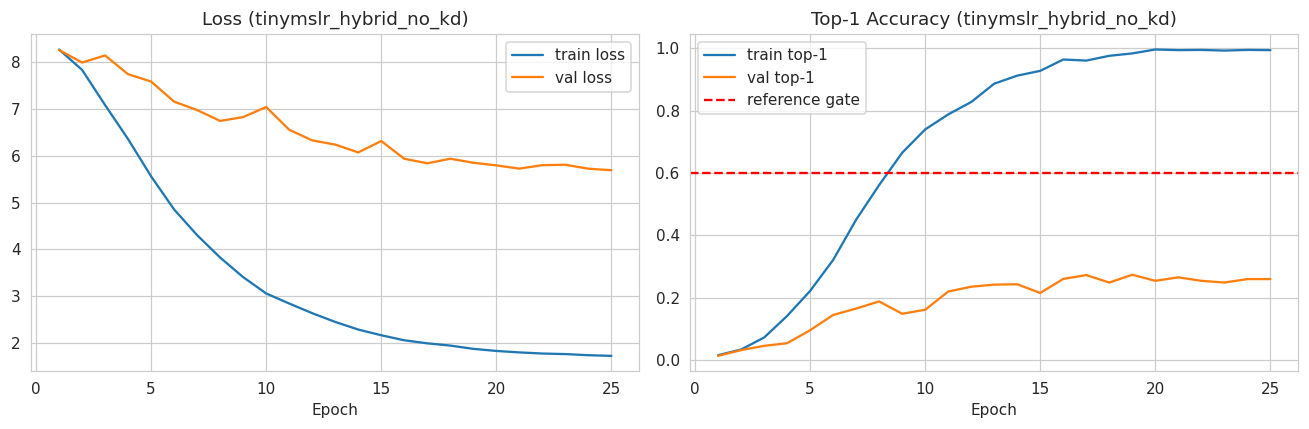

Best-checkpoint validation top-1: 0.274
Reference gate (0.60): not reached -- soft reference only, this notebook's primary output is the energy/carbon profile, not chasing this threshold


In [11]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss_curve = [h["val_loss"] for h in history]
train_top1 = [h["train_top1"] for h in history]
val_top1_curve = [h["val_top1"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, train_loss, label="train loss")
axes[0].plot(epochs_ran, val_loss_curve, label="val loss")
axes[0].set_title(f"Loss ({CONFIG.MODEL_TAG})"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_ran, train_top1, label="train top-1")
axes[1].plot(epochs_ran, val_top1_curve, label="val top-1")
axes[1].axhline(CONFIG.ACCURACY_GATE_THRESHOLD, color="red", linestyle="--", label="reference gate")
axes[1].set_title(f"Top-1 Accuracy ({CONFIG.MODEL_TAG})"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(CONFIG.OUTPUT_DIR / f"{CONFIG.MODEL_TAG}_train_val_curves.png", dpi=130, bbox_inches="tight")
plt.show()

best_epoch_val_top1 = best_val_top1
print(f"Best-checkpoint validation top-1: {best_epoch_val_top1:.3f}")
print(f"Reference gate ({CONFIG.ACCURACY_GATE_THRESHOLD:.2f}): "
      f"{'reached' if best_epoch_val_top1 >= CONFIG.ACCURACY_GATE_THRESHOLD else 'not reached'} "
      f"-- soft reference only, this notebook's primary output is the energy/carbon profile, "
      f"not chasing this threshold")


## 9. Test-Set Evaluation & Inference Energy Profiling

Same accuracy/energy protocol as notebooks 1-4, plus a look at the adaptive fusion gate's mean
weights over the test set — a distinctive, interpretable feature of this architecture that the
other four notebooks don't have (paper Eq. 14).

In [12]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_true, all_pred, all_top5, all_gate_weights = [], [], [], []
    for frames, labels in loader:
        frames = frames.to(device)
        logits, _aux_c, _aux_s, gate_weights = model(frames)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        top1 = probs.argmax(axis=1)
        k = min(5, NUM_CLASSES)
        top5 = probs.argsort(axis=1)[:, ::-1][:, :k]
        all_true.extend(labels.numpy().tolist())
        all_pred.extend(top1.tolist())
        all_top5.append(top5)
        all_gate_weights.append(gate_weights.cpu().numpy())
    return {
        "y_true": np.array(all_true),
        "y_pred": np.array(all_pred),
        "top5": np.concatenate(all_top5, axis=0),
        "gate_weights": np.concatenate(all_gate_weights, axis=0),
    }


# --- Accuracy pass: single, deterministic, this is the number reported for accuracy ---
test_preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
test_top1 = (test_preds["y_true"] == test_preds["y_pred"]).mean()
test_top5 = np.mean([t in top5 for t, top5 in zip(test_preds["y_true"], test_preds["top5"])])
print(f"Test Top-1: {test_top1:.3f} | Test Top-5: {test_top5:.3f} | Test clips: {len(test_dataset)}")

_labels = list(range(NUM_CLASSES))
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    test_preds["y_true"], test_preds["y_pred"], labels=_labels, average="weighted", zero_division=0)
print(f"Macro F1: {macro_f1:.3f} | Weighted F1: {weighted_f1:.3f}")

# --- Adaptive fusion gate weights (paper Eq. 14) -- a quick look at which branch the
# model leans on over the test set, since that's a distinctive, interpretable feature
# of this architecture the other four notebooks don't have. ---
mean_gate_weights = test_preds["gate_weights"].mean(axis=0)
print(f"Mean fusion gate weights over test set -- CNN (ConvNeXt): {mean_gate_weights[0]:.3f}, "
      f"Transformer (Swin): {mean_gate_weights[1]:.3f}")

# --- Energy-instrumented inference passes ---
# Same protocol as notebooks 1-4: repeated full test-set passes for a stable
# energy-per-inference reading, separate from the single deterministic accuracy pass.
# Peak GPU memory and per-clip latency during inference (paper review Minor Issue #10:
# neither was reported anywhere in the original submission).
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

inference_energy_per_pass_kwh = []
inference_latency_seconds_per_pass = []
if CODECARBON_AVAILABLE:
    for pass_idx in range(CONFIG.INFERENCE_PROFILING_PASSES):
        tracker = EmissionsTracker(
            project_name=f"{CONFIG.MODEL_TAG}_inference_pass{pass_idx}",
            output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
            save_to_file=False, allow_multiple_runs=True,
        )
        tracker.start()
        _pass_t0 = time.time()
        with torch.no_grad():
            for frames, _ in test_loader:
                frames = frames.to(CONFIG.DEVICE)
                _ = model(frames)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        inference_latency_seconds_per_pass.append(time.time() - _pass_t0)
        tracker.stop()
        emissions_data = tracker.final_emissions_data
        if emissions_data is not None:
            inference_energy_per_pass_kwh.append(emissions_data.energy_consumed)

PEAK_INFERENCE_GPU_MEMORY_GB = (
    round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
    if torch.cuda.is_available() else None
)
LATENCY_MS_PER_CLIP = (
    float(np.mean(inference_latency_seconds_per_pass)) / len(test_dataset) * 1000
    if inference_latency_seconds_per_pass else None
)
print(f"Peak GPU memory during inference: {PEAK_INFERENCE_GPU_MEMORY_GB} GB"
      if PEAK_INFERENCE_GPU_MEMORY_GB is not None else "Peak GPU memory during inference: N/A (no GPU)")
print(f"Mean latency per single-clip inference: {LATENCY_MS_PER_CLIP:.2f} ms"
      if LATENCY_MS_PER_CLIP is not None else "Mean latency per single-clip inference: N/A")

if inference_energy_per_pass_kwh:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = float(np.mean(inference_energy_per_pass_kwh))
    ENERGY_PER_CLIP_KWH = MEAN_INFERENCE_ENERGY_PER_PASS_KWH / len(test_dataset)
    print(f"\nMean energy per full test-set pass ({len(test_dataset)} clips): "
          f"{MEAN_INFERENCE_ENERGY_PER_PASS_KWH:.6f} kWh, across {len(inference_energy_per_pass_kwh)} passes")
    print(f"Estimated energy per single-clip inference: {ENERGY_PER_CLIP_KWH * 1e6:.2f} mWh")
else:
    MEAN_INFERENCE_ENERGY_PER_PASS_KWH = None
    ENERGY_PER_CLIP_KWH = None
    print("\nInference energy profiling skipped (codecarbon not installed).")


Test Top-1: 0.329 | Test Top-5: 0.647 | Test clips: 1409
Macro F1: 0.333 | Weighted F1: 0.334
Mean fusion gate weights over test set -- CNN (ConvNeXt): 1.000, Transformer (Swin): 0.000
Peak GPU memory during inference: 2.432 GB
Mean latency per single-clip inference: 164.73 ms

Mean energy per full test-set pass (1409 clips): 0.006237 kWh, across 3 passes
Estimated energy per single-clip inference: 4.43 mWh


### 9b. External Accuracy Reference Points (Not Reproduced Locally)

**Paper review Major Issue #3:** this study only compares its own five models against each
other. Without an external reference point, a reader cannot tell whether this notebook's
top-1 accuracy on the 100-class ASL Citizen pilot is competitive, mediocre, or unusually low
for the task -- the accuracy ceiling could reflect task difficulty at this scale just as
easily as an architectural or protocol limitation.

We do **not** reproduce these external numbers in this notebook (different class subsets,
splits, and training budgets make a like-for-like re-run out of scope for a single-model
green-computing unit), but they are recorded here so the number produced above can be read
in context rather than in isolation:

- **Alkhoraif et al. (2026)** report state-of-the-art accuracy on ASL Citizen (among other
  datasets) using a two-stream Swin-Transformer ensemble combining appearance and pose
  modalities -- a substantially heavier, multi-modal pipeline than any single model in this
  family.
- **Brettmann et al. (2025)** report that a VideoMAE-based ViViT variant substantially
  outperforms a traditional CNN baseline on WLASL100, a comparable-scale (100-class)
  word-level sign recognition benchmark.
- **Shawon et al. (2026)** compare VideoMAE, ViViT, and TimeSformer -- the same TimeSformer
  family used as this study's heavy Transformer entry -- on Bangla Sign Language datasets,
  finding video-Transformer accuracy sensitive to dataset size, frame rate, and signer
  variation.

None of these three report training or inference energy alongside their accuracy figures,
which is precisely the gap this five-model family's green-computing instrumentation exists
to fill -- but their accuracy numbers are the closest available external reference for
judging whether this notebook's own top-1 figure is in a reasonable range for a 100-class
word-level sign recognition task. A future revision could re-run one of these external
methods on this exact 100-class split to make the comparison direct rather than contextual.

## 10. Green-Computing Accounting — Carbon, Amortization, Efficiency

Same Eq. (1) / Eq. (2) / amortized-carbon math and constants as notebooks 1-4.

In [13]:
def fmt(value, spec=".4f", suffix=""):
    return "N/A" if value is None else f"{value:{spec}}{suffix}"


GRID_INTENSITY = CONFIG.GRID_CARBON_INTENSITY_KG_PER_KWH  # kg CO2e / kWh -- Eq. (1) in the proposal


def kwh_to_co2_kg(kwh):
    return None if kwh is None else kwh * GRID_INTENSITY


# --- Eq. (1): energy -> carbon ---
train_co2_kg_estimated = kwh_to_co2_kg(TOTAL_TRAIN_ENERGY_KWH)
inference_co2_kg_per_clip = kwh_to_co2_kg(ENERGY_PER_CLIP_KWH)

train_co2_g = None if train_co2_kg_estimated is None else train_co2_kg_estimated * 1000
inference_co2_mg_per_clip = None if inference_co2_kg_per_clip is None else inference_co2_kg_per_clip * 1e6

print("[Eq. 1] Estimated total training CO2e:", fmt(train_co2_g, ".2f", " g"),
      f"(grid intensity assumption: {GRID_INTENSITY} kg/kWh)")
print("[Eq. 1] Estimated CO2e per inference:", fmt(inference_co2_mg_per_clip, ".3f", " mg"))

# --- Faculty feedback: amortized training carbon / expected inference volume ---
# CONFIG.EXPECTED_INFERENCE_VOLUME is a placeholder deployment-scenario assumption
# (see CONFIG comment) -- swap in a properly justified/cited figure before this goes
# in the paper.
amortized_training_co2_per_inference_kg = None
if train_co2_kg_estimated is not None:
    amortized_training_co2_per_inference_kg = train_co2_kg_estimated / CONFIG.EXPECTED_INFERENCE_VOLUME

total_lifecycle_co2_per_inference_kg = None
if amortized_training_co2_per_inference_kg is not None and inference_co2_kg_per_clip is not None:
    total_lifecycle_co2_per_inference_kg = (
        amortized_training_co2_per_inference_kg + inference_co2_kg_per_clip
    )

amortized_mg = None if amortized_training_co2_per_inference_kg is None else amortized_training_co2_per_inference_kg * 1e6
lifecycle_mg = None if total_lifecycle_co2_per_inference_kg is None else total_lifecycle_co2_per_inference_kg * 1e6

print(f"\nAmortized training CO2e per inference "
      f"(assuming {CONFIG.EXPECTED_INFERENCE_VOLUME:,} lifetime inferences):", fmt(amortized_mg, ".4f", " mg"))
print("Total lifecycle CO2e per inference (amortized training + marginal inference):",
      fmt(lifecycle_mg, ".4f", " mg"))

# --- Eq. (2): accuracy-per-carbon efficiency metric ---
def efficiency_metric(accuracy_pct, co2_g):
    if co2_g is None or co2_g == 0:
        return None
    return accuracy_pct / co2_g


eta_train = efficiency_metric(test_top1 * 100, train_co2_g)
lifecycle_co2_g_per_inference = None if lifecycle_mg is None else lifecycle_mg / 1000
eta_lifecycle_per_inference = efficiency_metric(test_top1 * 100, lifecycle_co2_g_per_inference)

print("\n[Eq. 2] eta_acc/carbon (training-total basis):", fmt(eta_train, ".4f", " % per g CO2e"))
print("[Eq. 2] eta_acc/carbon (per-inference lifecycle basis):",
      fmt(eta_lifecycle_per_inference, ".6f", " % per g CO2e"))

# --- Lifecycle sensitivity analysis (paper review Recommended fix: the single 100,000-
# inference deployment-volume assumption was never sensitivity-tested in the original
# submission). Recomputes eta_life at each volume in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY
# so the model's efficiency ranking can be checked for stability across plausible scales,
# not just trusted at one arbitrary point estimate.
lifecycle_sensitivity = []
for n_inf in CONFIG.DEPLOYMENT_VOLUME_SENSITIVITY:
    amortized_kg_n = None if train_co2_kg_estimated is None else train_co2_kg_estimated / n_inf
    lifecycle_kg_n = None
    if amortized_kg_n is not None and inference_co2_kg_per_clip is not None:
        lifecycle_kg_n = amortized_kg_n + inference_co2_kg_per_clip
    lifecycle_g_n = None if lifecycle_kg_n is None else lifecycle_kg_n * 1000
    eta_life_n = efficiency_metric(test_top1 * 100, lifecycle_g_n)
    lifecycle_sensitivity.append({
        "deployment_volume_inferences": n_inf,
        "lifecycle_co2_mg_per_inference": None if lifecycle_kg_n is None else lifecycle_kg_n * 1e6,
        "eta_lifecycle_pct_per_g_co2e": eta_life_n,
    })

print("\n[Sensitivity] eta_life across deployment-volume assumptions (not just the single",
      f"{CONFIG.EXPECTED_INFERENCE_VOLUME:,}-inference point estimate):")
for row in lifecycle_sensitivity:
    print(f"  N={row['deployment_volume_inferences']:>10,}  "
          f"lifecycle_CO2e/inference={fmt(row['lifecycle_co2_mg_per_inference'], '.4f', ' mg')}  "
          f"eta_life={fmt(row['eta_lifecycle_pct_per_g_co2e'], '.6f', ' %/g CO2e')}")

# --- Parametric deployment-threshold check (paper review Minor Issue #7: the 60% soft
# accuracy reference is author-defined, not externally justified). Reports whether this
# model clears each candidate threshold rather than resting the deployment narrative on
# one unjustified line.
threshold_check = {
    f"clears_{int(t*100)}pct_threshold": bool(test_top1 >= t)
    for t in CONFIG.ACCURACY_GATE_THRESHOLDS_FOR_SENSITIVITY
}
print("\n[Sensitivity] Deployment-threshold check (test_top1 =", f"{test_top1:.3f}):")
for k, v in threshold_check.items():
    print(f"  {k}: {v}")


[Eq. 1] Estimated total training CO2e: 97.34 g (grid intensity assumption: 0.41272 kg/kWh)
[Eq. 1] Estimated CO2e per inference: 1.827 mg

Amortized training CO2e per inference (assuming 100,000 lifetime inferences): 0.9734 mg
Total lifecycle CO2e per inference (amortized training + marginal inference): 2.8003 mg

[Eq. 2] eta_acc/carbon (training-total basis): 0.3376 % per g CO2e
[Eq. 2] eta_acc/carbon (per-inference lifecycle basis): 11734.703344 % per g CO2e

[Sensitivity] eta_life across deployment-volume assumptions (not just the single 100,000-inference point estimate):
  N=    10,000  lifecycle_CO2e/inference=11.5611 mg  eta_life=2842.306466 %/g CO2e
  N=   100,000  lifecycle_CO2e/inference=2.8003 mg  eta_life=11734.703344 %/g CO2e
  N= 1,000,000  lifecycle_CO2e/inference=1.9242 mg  eta_life=17077.564147 %/g CO2e

[Sensitivity] Deployment-threshold check (test_top1 = 0.329):
  clears_50pct_threshold: False
  clears_60pct_threshold: False
  clears_70pct_threshold: False


## 10b. Multi-Seed Repetition for Statistical Validity

Repeats the full train+eval pipeline across `CONFIG.SEEDS` and reports mean +/- SD for every headline metric (paper review Major Issue #2). This is the single most compute-expensive addition in this notebook -- it multiplies total training cost by `len(CONFIG.SEEDS)`, which is itself worth reporting as part of this study's own carbon cost of doing rigorous science.

In [14]:
# --- Multi-seed repetition for statistical validity (paper review Major Issue #2: every
# comparative claim in the original single-run submission rested on n=1 per model, with
# no seeds, no variance, no CI anywhere -- self-disclosed but never fixed). The seed
# CONFIG.SEED run above (Sections 7-9) is reused as the first data point; this cell repeats
# the full train+eval pipeline for every remaining seed in CONFIG.SEEDS and reports
# mean +/- SD for every headline metric, so the model-vs-model rankings in the cross-model
# comparison can finally be checked against run-to-run noise.

MULTI_SEED_RESULTS = [{
    "seed": CONFIG.SEED,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "total_train_co2_g": train_co2_g,
    "eta_acc_per_carbon_training_basis": eta_train,
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
}]


def _train_and_evaluate_one_seed(seed):
    """Rebuilds the model from scratch under a fresh seed, retrains it end-to-end with
    the same protocol as the primary run (Section 7), evaluates it, and returns the same
    headline metrics as the primary run's globals -- so it can be folded into
    MULTI_SEED_RESULTS on equal footing."""
    global model, optimizer, scheduler

    seed_everything(seed)
    model = TinyMSLRHybridModel(num_classes=NUM_CLASSES).to(CONFIG.DEVICE)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=CONFIG.LR, weight_decay=CONFIG.WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG.EPOCHS_FULL)

    _best_val_top1 = -float("inf")
    _epochs_without_improvement = 0
    _best_state_dict = None
    _per_epoch_energy_kwh = []
    _epochs_ran = 0

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(CONFIG.DEVICE)

    _t0 = time.time()
    for epoch in range(1, CONFIG.EPOCHS_FULL + 1):
        tracker = None
        if CODECARBON_AVAILABLE:
            tracker = EmissionsTracker(
                project_name=f"{CONFIG.MODEL_TAG}_seed{seed}_epoch{epoch}",
                output_dir=str(CONFIG.OUTPUT_DIR), log_level="error",
                save_to_file=False, allow_multiple_runs=True,
            )
            tracker.start()

        train_metrics = run_epoch(train_loader, train=True)
        val_metrics = run_epoch(val_loader, train=False)
        scheduler.step()
        _epochs_ran = epoch

        epoch_energy_kwh = None
        if tracker is not None:
            tracker.stop()
            emissions_data = tracker.final_emissions_data
            if emissions_data is not None:
                epoch_energy_kwh = emissions_data.energy_consumed
        if epoch_energy_kwh is not None:
            _per_epoch_energy_kwh.append(epoch_energy_kwh)

        is_best = val_metrics["top1"] > _best_val_top1
        if is_best:
            _best_val_top1 = val_metrics["top1"]
            _epochs_without_improvement = 0
            _best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            _epochs_without_improvement += 1
            if (epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
                    and _epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
                print(f"  [seed {seed}] early stopping at epoch {epoch}")
                break

    wall_min = (time.time() - _t0) / 60
    if _best_state_dict is not None:
        model.load_state_dict(_best_state_dict)
    model.eval()

    peak_train_mem_gb = (
        round(torch.cuda.max_memory_allocated(CONFIG.DEVICE) / (1024**3), 3)
        if torch.cuda.is_available() else None
    )
    total_train_energy_kwh = sum(_per_epoch_energy_kwh) if _per_epoch_energy_kwh else None

    preds = collect_predictions(model, test_loader, CONFIG.DEVICE)
    seed_test_top1 = float((preds["y_true"] == preds["y_pred"]).mean())
    seed_test_top5 = float(np.mean([t in top5 for t, top5 in zip(preds["y_true"], preds["top5"])]))

    train_co2_kg_seed = kwh_to_co2_kg(total_train_energy_kwh)
    train_co2_g_seed = None if train_co2_kg_seed is None else train_co2_kg_seed * 1000
    eta_train_seed = efficiency_metric(seed_test_top1 * 100, train_co2_g_seed)

    print(f"  [seed {seed}] test_top1={seed_test_top1:.3f} epochs={_epochs_ran} "
          f"train_co2_g={fmt(train_co2_g_seed, '.2f')} wall_min={wall_min:.1f}")

    return {
        "seed": seed,
        "test_top1": seed_test_top1,
        "test_top5": seed_test_top5,
        "best_val_top1": float(_best_val_top1),
        "epochs_ran": _epochs_ran,
        "total_train_energy_kwh": total_train_energy_kwh,
        "total_train_co2_g": train_co2_g_seed,
        "eta_acc_per_carbon_training_basis": eta_train_seed,
        "wall_clock_train_minutes": wall_min,
        "peak_train_gpu_memory_gb": peak_train_mem_gb,
    }


for _seed in CONFIG.SEEDS:
    if _seed == CONFIG.SEED:
        continue
    print(f"\n=== Repeating full train+eval for seed={_seed} ===")
    MULTI_SEED_RESULTS.append(_train_and_evaluate_one_seed(_seed))

# --- Aggregate mean +/- SD across all collected seeds ---
import statistics as _stats


def _mean_sd(metric_key):
    vals = [r[metric_key] for r in MULTI_SEED_RESULTS if r.get(metric_key) is not None]
    if not vals:
        return None, None
    if len(vals) == 1:
        return vals[0], 0.0
    return _stats.mean(vals), _stats.stdev(vals)


MULTI_SEED_SUMMARY = {"n_seeds": len(MULTI_SEED_RESULTS), "seeds": [r["seed"] for r in MULTI_SEED_RESULTS]}
for _k in ["test_top1", "test_top5", "total_train_co2_g", "eta_acc_per_carbon_training_basis",
           "total_train_energy_kwh", "wall_clock_train_minutes"]:
    _m, _s = _mean_sd(_k)
    MULTI_SEED_SUMMARY[f"{_k}_mean"] = _m
    MULTI_SEED_SUMMARY[f"{_k}_std"] = _s

print(f"\n=== Multi-seed summary (n={MULTI_SEED_SUMMARY['n_seeds']} seeds: {MULTI_SEED_SUMMARY['seeds']}) ===")
for _k, _v in MULTI_SEED_SUMMARY.items():
    if _k in ("n_seeds", "seeds"):
        continue
    print(f"  {_k}: {fmt(_v, '.4f')}")



=== Repeating full train+eval for seed=123 ===
  [seed 123] early stopping at epoch 30
  [seed 123] test_top1=0.380 epochs=30 train_co2_g=116.79 wall_min=177.4

=== Repeating full train+eval for seed=2024 ===
  [seed 2024] early stopping at epoch 29
  [seed 2024] test_top1=0.332 epochs=29 train_co2_g=113.06 wall_min=171.7

=== Multi-seed summary (n=3 seeds: [42, 123, 2024]) ===
  test_top1_mean: 0.3468
  test_top1_std: 0.0285
  test_top5_mean: 0.6674
  test_top5_std: 0.0225
  total_train_co2_g_mean: 109.0651
  total_train_co2_g_std: 10.3218
  eta_acc_per_carbon_training_basis_mean: 0.3188
  eta_acc_per_carbon_training_basis_std: 0.0226
  total_train_energy_kwh_mean: 0.2643
  total_train_energy_kwh_std: 0.0250
  wall_clock_train_minutes_mean: 165.6657
  wall_clock_train_minutes_std: 15.6076


## 11. Model Card Export

Saves `green_metrics_tinymslr_hybrid_no_kd.json`, matching the earlier notebooks' schema plus
this notebook's caveat flags (`kd_implemented`, `param_count_matches_paper_2_7m_claim`) and the
mean fusion gate weights.

In [15]:
model_card = {
    "model_tag": CONFIG.MODEL_TAG,
    "architecture_family": "Hybrid CNN-Transformer (TinyMSLR-style, adaptive fusion, no KD)",
    "backbone": "ConvNeXt-Tiny+GRU (CNN branch) + Swin-Tiny (Transformer branch), both ImageNet-pretrained",
    "kd_implemented": False,
    "param_count_matches_paper_2_7m_claim": False,
    "num_classes": NUM_CLASSES,
    "top_k_classes_config": CONFIG.TOP_K_CLASSES,
    "frame_count": CONFIG.FRAME_COUNT,
    "image_size": CONFIG.IMAGE_SIZE,
    "params_total": n_params_total,
    "params_trainable": n_params_trainable,
    "gflops_per_inference": gflops_per_inference,
    "gflops_is_lower_bound": True,
    "test_top1": float(test_top1),
    "test_top5": float(test_top5),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "mean_gate_weight_cnn": float(mean_gate_weights[0]),
    "mean_gate_weight_transformer": float(mean_gate_weights[1]),
    "best_val_top1": float(best_val_top1),
    "epochs_ran": len(history),
    "wall_clock_train_minutes": wall_clock_train_minutes,
    "total_train_energy_kwh": TOTAL_TRAIN_ENERGY_KWH,
    "grid_carbon_intensity_kg_per_kwh": GRID_INTENSITY,
    "total_train_co2_g": train_co2_g,
    "energy_per_inference_kwh": ENERGY_PER_CLIP_KWH,
    "co2_per_inference_mg": inference_co2_mg_per_clip,
    "expected_inference_volume_assumption": CONFIG.EXPECTED_INFERENCE_VOLUME,
    "amortized_train_co2_per_inference_mg": amortized_mg,
    "total_lifecycle_co2_per_inference_mg": lifecycle_mg,
    "eta_acc_per_carbon_training_basis": eta_train,
    "eta_acc_per_carbon_lifecycle_basis": eta_lifecycle_per_inference,

    # --- Fields added in response to the paper review's Major/Minor issues ---
    "hardware_software_environment": HARDWARE_INFO,
    "signer_independence_report": SIGNER_INDEPENDENCE_REPORT,
    "peak_train_gpu_memory_gb": PEAK_TRAIN_GPU_MEMORY_GB,
    "peak_inference_gpu_memory_gb": PEAK_INFERENCE_GPU_MEMORY_GB,
    "latency_ms_per_clip_inference": LATENCY_MS_PER_CLIP,
    "lifecycle_carbon_sensitivity": lifecycle_sensitivity,
    "deployment_threshold_sensitivity": threshold_check,
    "multi_seed_results": MULTI_SEED_RESULTS,
    "multi_seed_summary": MULTI_SEED_SUMMARY,
    # Multi-seed mean/SD are the headline figures for cross-model comparison going
    # forward (paper review Major Issue #2) -- single-seed fields above are kept for
    # backward compatibility with the original schema, not as the primary result.
    "test_top1_mean": MULTI_SEED_SUMMARY.get("test_top1_mean"),
    "test_top1_std": MULTI_SEED_SUMMARY.get("test_top1_std"),
    "total_train_co2_g_mean": MULTI_SEED_SUMMARY.get("total_train_co2_g_mean"),
    "total_train_co2_g_std": MULTI_SEED_SUMMARY.get("total_train_co2_g_std"),
    "eta_acc_per_carbon_training_basis_mean": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_mean"),
    "eta_acc_per_carbon_training_basis_std": MULTI_SEED_SUMMARY.get("eta_acc_per_carbon_training_basis_std"),
}

model_card_path = CONFIG.OUTPUT_DIR / f"green_metrics_{CONFIG.MODEL_TAG}.json"
with open(model_card_path, "w") as f:
    json.dump(model_card, f, indent=2)

print(f"Model card saved to: {model_card_path}")
print("Two fields flag this notebook's documented scope cuts: 'kd_implemented': False "
      "(see Section 7) and 'param_count_matches_paper_2_7m_claim': False (see changelog) "
      "-- keep both in view when writing up this model in the paper's comparison table, "
      "and when this JSON joins the other four.")
display(pd.DataFrame([model_card]).T.rename(columns={0: "value"}))


Model card saved to: /kaggle/working/green_report_tinymslr_hybrid_no_kd/green_metrics_tinymslr_hybrid_no_kd.json
Two fields flag this notebook's documented scope cuts: 'kd_implemented': False (see Section 7) and 'param_count_matches_paper_2_7m_claim': False (see changelog) -- keep both in view when writing up this model in the paper's comparison table, and when this JSON joins the other four.


,value
model_tag,tinymslr_hybrid_no_kd
architecture_family,"Hybrid CNN-Transformer (TinyMSLR-style, adapti..."
backbone,ConvNeXt-Tiny+GRU (CNN branch) + Swin-Tiny (Tr...
kd_implemented,False
param_count_matches_paper_2_7m_claim,False
num_classes,100
top_k_classes_config,100
frame_count,16
image_size,224
params_total,60464904


## 12. Notes for the Paper / Next Steps

- **All 5 models in the family are now built.** Once this notebook runs, five `green_metrics_*.json`
  files exist: MobileNetV3-Small, ResNet-50, ViViT-Lite, TimeSformer, and this hybrid — enough
  for the full RQ1-RQ3 analysis and the accuracy-vs-carbon Pareto plot from the proposal's
  Section V-D. Building that plot/table is the natural next step, and it's deliberately not done
  here since it needs all five notebooks' actual run results, not just this one's.
- **Two honest limitations to carry into the paper, not paper over:** this notebook's parameter
  count doesn't match the source paper's claimed 2.7M (unreproducible without an unpublished
  compression config — see changelog), and it omits dual-teacher KD (a real, scoped-out
  training-time cost the source paper pays that this comparison doesn't). Both are legitimate,
  citable observations about reproducing "TinyML" claims from the literature, not embarrassing
  gaps to hide — say so plainly in the methodology section.
- **A genuinely interesting empirical question once this runs:** does the hybrid's combination
  of both architecture families land it *between* the CNN and Transformer families on the
  accuracy-per-carbon efficiency metric (Eq. 2), or does running two full backbones in parallel
  make it the least efficient of all five regardless of any accuracy gain? That's an actual
  result, not something to assume in either direction before the numbers are in.
- Numbers from this notebook are real once you run it on Kaggle — nothing above is pre-filled or
  asserted in advance.